In [5]:
from pathlib import Path
import sys
import json
import random

import matplotlib.pyplot as plt
import torch

# Ensure project imports work when notebook cwd is notebooks/
PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from data_pipeline import get_arithmetic_dataloader
from models import ResNet18LateFusion, SimpleFCLateFusion

torch.set_grad_enabled(False)
random.seed(42)
torch.manual_seed(42)

In [7]:
# PROJECT_ROOT

In [8]:
# Find the most recent run with a best checkpoint
runs_root = PROJECT_ROOT / "runs" / "baseline"
candidate_runs = sorted(
    [p for p in runs_root.glob("*") if (p / "best.pt").exists()],
    key=lambda p: p.stat().st_mtime,
    reverse=True,
 )

if not candidate_runs:
    raise FileNotFoundError("No checkpoint found under runs/baseline/*/best.pt")


In [10]:
# candidate_runs

In [11]:

run_dir = candidate_runs[1]
ckpt_path = run_dir / "best.pt"
cfg_path = run_dir / "config.json"

with cfg_path.open("r") as f:
    cfg = json.load(f)

print(f"Using run directory: {run_dir.name}")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
)

test_ops = cfg["data"].get("test_ops") or cfg["data"]["ops"]
if cfg["model"]["op_embedding_type"] == "embedding":
    model_ops = sorted(set(cfg["data"]["ops"]) | set(test_ops))
else:
    model_ops = cfg["data"]["ops"]

if cfg["model"]["name"] == "resnet18":
    model = ResNet18LateFusion(
        ops=model_ops,
        num_classes=cfg["model"]["num_classes"],
        op_embed_dim=cfg["model"]["op_embed_dim"],
        mlp_hidden=cfg["model"]["mlp_hidden"],
        op_embedding_type=cfg["model"]["op_embedding_type"],
    )
elif cfg["model"]["name"] == "simple_fc2":
    model = SimpleFCLateFusion(
        ops=model_ops,
        num_classes=cfg["model"]["num_classes"],
        op_embed_dim=cfg["model"]["op_embed_dim"],
        mlp_hidden=cfg["model"]["mlp_hidden"],
        op_embedding_type=cfg["model"]["op_embedding_type"],
    )
else:
    raise ValueError(f"Unknown model name: {cfg['model']['name']}")

checkpoint = torch.load(ckpt_path, map_location=device)
model.load_state_dict(checkpoint["model"])
model.to(device)
model.eval()

test_loader = get_arithmetic_dataloader(
    dataset_name=cfg["data"]["dataset"],
    batch_size=32,
    ops=test_ops,
    is_train=False,
    data_root=cfg["data"]["data_root"],
    num_workers=cfg["data"]["num_workers"],
)

print(f"Model loaded on: {device}")
print(f"Checkpoint epoch: {checkpoint.get('epoch', 'n/a')}")
print(f"Checkpoint test acc: {checkpoint.get('test_acc', 'n/a')}")

Using run directory: 20260416-122015-resnet-fourier-ops
Model loaded on: mps
Checkpoint epoch: 2
Checkpoint test acc: 0.001668216660618782


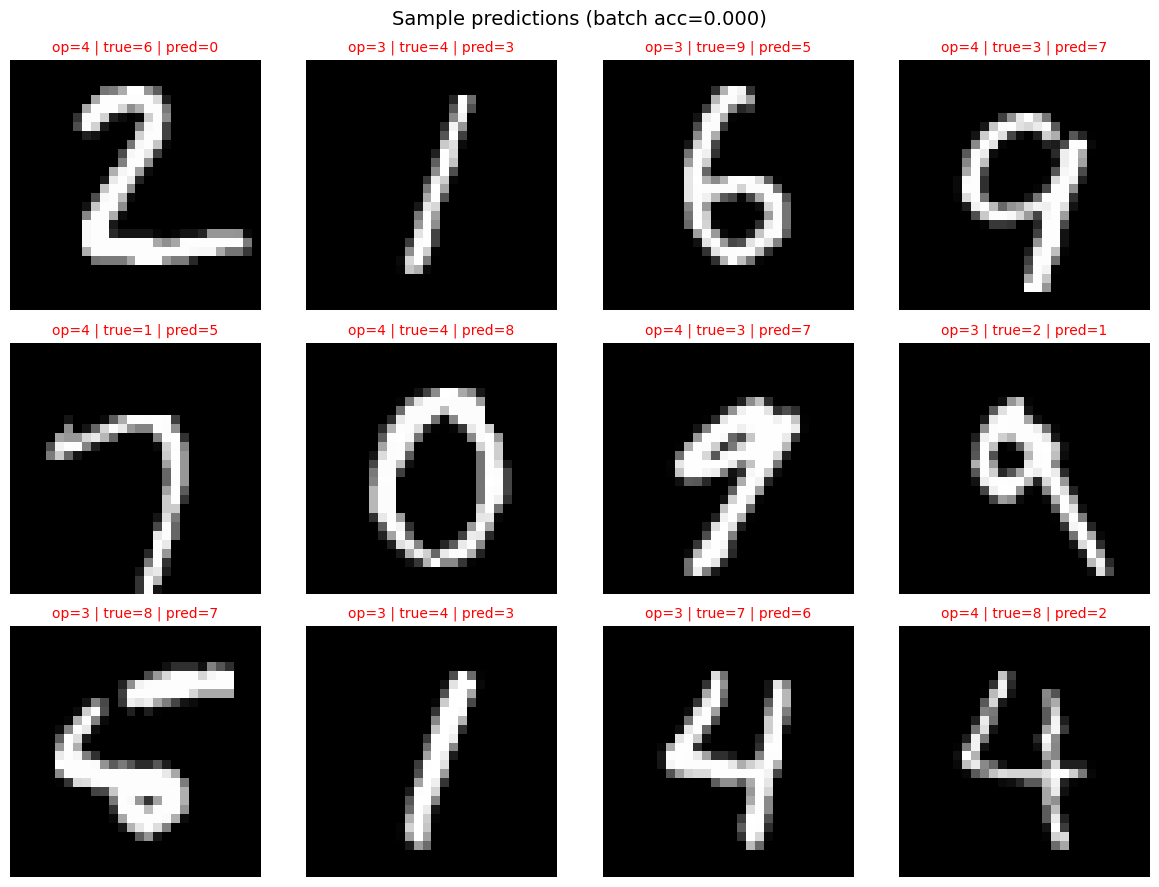

In [12]:
# Run predictions for one batch and visualize examples
batch = next(iter(test_loader))
ctx_img = batch["ctx_img"].to(device)
op = batch["op"].to(device)
tgt = batch["tgt_label"].to(device)

logits = model(ctx_img, op)
pred = logits.argmax(dim=1)

num_show = 12
idxs = torch.randperm(ctx_img.size(0))[:num_show]

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for ax, i in zip(axes, idxs):
    img = ctx_img[i].cpu().squeeze(0)
    true_label = int(tgt[i].cpu().item())
    pred_label = int(pred[i].cpu().item())
    op_val = float(op[i].cpu().item())

    ax.imshow(img, cmap="gray")
    ax.axis("off")
    color = "green" if true_label == pred_label else "red"
    ax.set_title(
        f"op={op_val:.0f} | true={true_label} | pred={pred_label}",
        color=color,
        fontsize=10,
    )

for j in range(len(idxs), len(axes)):
    axes[j].axis("off")

batch_acc = (pred == tgt).float().mean().item()
plt.suptitle(f"Sample predictions (batch acc={batch_acc:.3f})", fontsize=14)
plt.tight_layout()
plt.show()

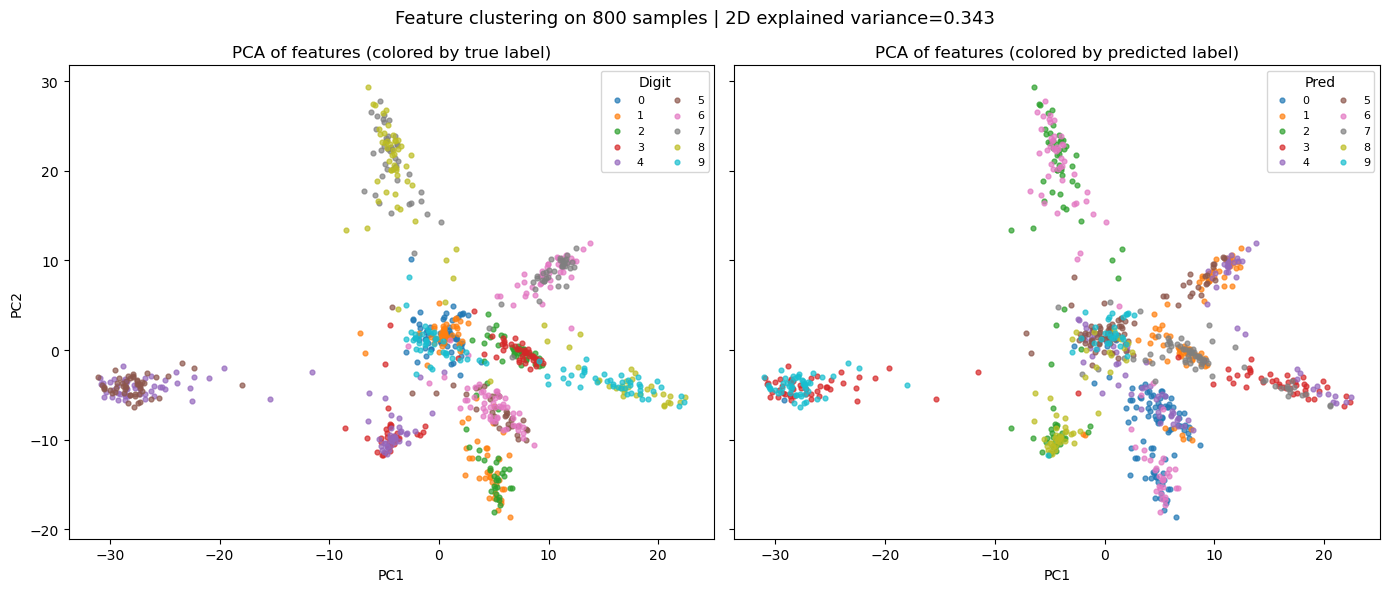

Sampled accuracy on plotted set: 0.0000
Unique ops in plotted set: [3.0, 4.0]


In [13]:
# Extract intermediate features, reduce to 2D with PCA, and visualize clusters
max_samples = 800
n_batches = 25

all_feats = []
all_true = []
all_pred = []
all_ops = []

def extract_features(m, img, op_vals):
    # ResNet path: use encoder output (penultimate features).
    if hasattr(m, "encoder"):
        return m.encoder(img)

    # Simple FC path: use hidden activation after first Linear+ReLU block.
    if hasattr(m, "op_embed") and hasattr(m, "net"):
        img_flat = img.flatten(start_dim=1)
        op_vec = m.op_embed(op_vals)
        fused = torch.cat([img_flat, op_vec], dim=1)
        hidden = m.net[1](m.net[0](fused))
        return hidden

    raise ValueError("Unsupported model type for feature extraction")

for b_idx, b in enumerate(test_loader):
    if b_idx >= n_batches:
        break

    img_b = b["ctx_img"].to(device)
    op_b = b["op"].to(device)
    y_b = b["tgt_label"].to(device)

    feats_b = extract_features(model, img_b, op_b)
    logits_b = model(img_b, op_b)
    pred_b = logits_b.argmax(dim=1)

    all_feats.append(feats_b.detach().cpu())
    all_true.append(y_b.detach().cpu())
    all_pred.append(pred_b.detach().cpu())
    all_ops.append(op_b.detach().cpu())

features = torch.cat(all_feats, dim=0)[:max_samples]
y_true = torch.cat(all_true, dim=0)[:max_samples]
y_pred = torch.cat(all_pred, dim=0)[:max_samples]
ops_used = torch.cat(all_ops, dim=0)[:max_samples]

# PCA via torch.pca_lowrank
features_centered = features - features.mean(dim=0, keepdim=True)
q = min(10, features_centered.shape[0], features_centered.shape[1])
_, s, v = torch.pca_lowrank(features_centered, q=q)
coords_2d = features_centered @ v[:, :2]

explained_var = (s ** 2)
explained_ratio_2d = (explained_var[:2].sum() / explained_var.sum()).item()

x = coords_2d[:, 0].numpy()
y = coords_2d[:, 1].numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

for d in range(10):
    mask = (y_true.numpy() == d)
    if mask.any():
        axes[0].scatter(x[mask], y[mask], s=12, alpha=0.7, label=str(d))
axes[0].set_title("PCA of features (colored by true label)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(title="Digit", ncol=2, fontsize=8)

for d in range(10):
    mask = (y_pred.numpy() == d)
    if mask.any():
        axes[1].scatter(x[mask], y[mask], s=12, alpha=0.7, label=str(d))
axes[1].set_title("PCA of features (colored by predicted label)")
axes[1].set_xlabel("PC1")
axes[1].legend(title="Pred", ncol=2, fontsize=8)

plt.suptitle(
    f"Feature clustering on {len(features)} samples | 2D explained variance={explained_ratio_2d:.3f}",
    fontsize=13,
)
plt.tight_layout()
plt.show()

acc = (y_pred == y_true).float().mean().item()
print(f"Sampled accuracy on plotted set: {acc:.4f}")
print(f"Unique ops in plotted set: {sorted(set(ops_used.tolist()))}")